# The 2D Ising model: learning Monte Carlo with a Markov chain

**Guided undergraduate project | Spin configurations and temperature**

You already used Monte Carlo to estimate $\pi$ with independent random points, and you used a random walk to move between states. Here both ideas meet: a **Markov chain** generates successive spin configurations, and we take **Monte Carlo averages** of their magnetization and energy.

**Learning goals:** build a square lattice of interacting spins; calculate its energy; implement one Metropolis spin flip; watch order disappear as temperature rises; and distinguish a finite-lattice crossover from the sharp transition of an infinite system.

Use only NumPy, Matplotlib, and Python's standard-library `random`. Run cells in order. This is a new learning project, not a claim of earlier coursework.


## 1. What is a spin configuration?

Each site of an $L\times L$ square grid has a spin $s_{ij}=+1$ (up) or $-1$ (down). Each spin interacts with its four nearest neighbors. Set the coupling $J=1$, Boltzmann's constant $k_B=1$, and external field $H=0$:

$$E=-J\sum_{\langle i,j\rangle}s_i s_j.$$

The sum counts each neighboring pair **once**. Aligned neighbors contribute $-J$; opposite neighbors contribute $+J$. At low temperature, aligned patches tend to be favored. At high temperature, random motion increasingly disrupts them.

We use **periodic boundaries**: a spin on the left edge is also adjacent to the corresponding spin on the right edge, and similarly for top and bottom.


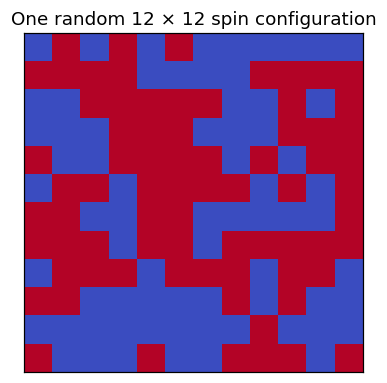

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import random

# NumPy creates initial spins; Python random selects proposals and acceptance draws.
# Seed both streams for reproducible runs, without restarting them at each temperature.
random.seed(18)
np.random.seed(18)
J = 1.0

def make_spins(L, ordered=False):
    if ordered:
        # All-up is an ordered initial state, not an equilibrium sample at arbitrary T.
        return np.ones((L, L), dtype=int)
    # Unbiased +/-1 spins give a disordered starting configuration.
    return np.random.choice([-1, 1], size=(L, L))

spins = make_spins(12)
plt.figure(figsize=(4, 4))
plt.imshow(spins, cmap='coolwarm', vmin=-1, vmax=1, interpolation='nearest')
plt.title('One random 12 × 12 spin configuration')
plt.xticks([])
plt.yticks([])
plt.show()


## 2. Calculate energy and magnetization

Magnetization is the sum of spins, $M=\sum_i s_i$. Divide by $N=L^2$ to obtain magnetization **per spin** $m=M/N$. Thus an all-up lattice has $m=1$, an all-down lattice has $m=-1$, and a balanced lattice has $m\approx0$.

**Task.** Write an energy function that counts only right and lower neighbors for each site, avoiding double counting. Check that the fully aligned state has $E=-2JN$ because each site contributes one right and one lower bond.


In [2]:
def total_energy(spins, J=1.0):
    L = len(spins)
    E = 0.0
    for row in range(L):
        for col in range(L):
            # Modulo wraps across the boundary: opposite edges are neighboring sites.
            right = spins[row, (col + 1) % L]
            below = spins[(row + 1) % L, col]
            # Counting right and below includes each bond once; all four would double E.
            E = E - J*spins[row, col]*(right + below)
    return E

def total_magnetization(spins):
    # Sum signed spins first; division by lattice size later gives magnetization per spin.
    return int(np.sum(spins))

ordered = make_spins(12, ordered=True)
N = ordered.size
print('All-up energy:', total_energy(ordered), '| expected:', -2*J*N)
print('All-up magnetization per spin:', total_magnetization(ordered)/N)
print('Random-state magnetization per spin:', total_magnetization(spins)/spins.size)
assert total_energy(ordered) == -2*J*N


All-up energy: -288.0 | expected: -288.0
All-up magnetization per spin: 1.0
Random-state magnetization per spin: 0.027777777777777776


## 3. A single Metropolis flip

Imagine changing a selected spin $s$ to $-s$. Only its four bonds change. If the sum of its neighbors is $S$, the energy change is

$$\Delta E=2JsS.$$

At temperature $T$ (with $k_B=1$), accept every move with $\Delta E\leq0$. If $\Delta E>0$, accept it with probability $\exp(-\Delta E/T)$. This occasionally permits an unfavorable move, especially at high $T$. A rejected move leaves the configuration unchanged.

This sequence is a **Markov chain**: the next configuration depends on the current configuration and a new random proposal. One **sweep** is $N$ attempted single-spin flips, not necessarily one accepted flip per site.


In [3]:
def metropolis_sweep(spins, T, E, M, J=1.0):
    L = len(spins)
    accepted = 0
    # One sweep is N random proposals WITH replacement; some sites may be chosen repeatedly.
    for attempt in range(L*L):
        row = random.randrange(L)
        col = random.randrange(L)
        spin = spins[row, col]
        neighbors = (spins[(row+1) % L, col] + spins[(row-1) % L, col]
                     + spins[row, (col+1) % L] + spins[row, (col-1) % L])
        # Flipping s reverses its four bond energies: Delta E = 2*J*s*sum(neighbors).
        delta_E = 2*J*spin*neighbors

        # Symmetric spin proposals plus this acceptance rule target exp(-E/T) at T>0.
        # Favorable/neutral moves are accepted; uphill moves are accepted probabilistically.
        if delta_E <= 0 or random.random() < np.exp(-delta_E/T):
            spins[row, col] = -spin
            # Only four bonds change, so update energy locally instead of summing the lattice.
            E = E + delta_E
            # The selected spin changes from s to -s, so its contribution changes by -2*s.
            M = M - 2*spin
            accepted = accepted + 1
    return E, M, accepted

# Check that updating E and M during flips agrees with a fresh calculation.
check = make_spins(12)
E = total_energy(check)
M = total_magnetization(check)
for sweep in range(30):
    E, M, accepted = metropolis_sweep(check, 2.3, E, M)
assert abs(E - total_energy(check)) < 1e-10
assert M == total_magnetization(check)
print('Energy and magnetization updates agree with direct calculation.')


Energy and magnetization updates agree with direct calculation.


## 4. What do low and high temperatures look like?

**Task.** Start from all-up spins, perform 350 sweeps at each of three temperatures, and show the final configurations. We choose $T=1.5$, $2.3$, and $3.5$ in units of $J/k_B$. Near the transition you may see sizeable patches of both orientations; any one snapshot is only one configuration.


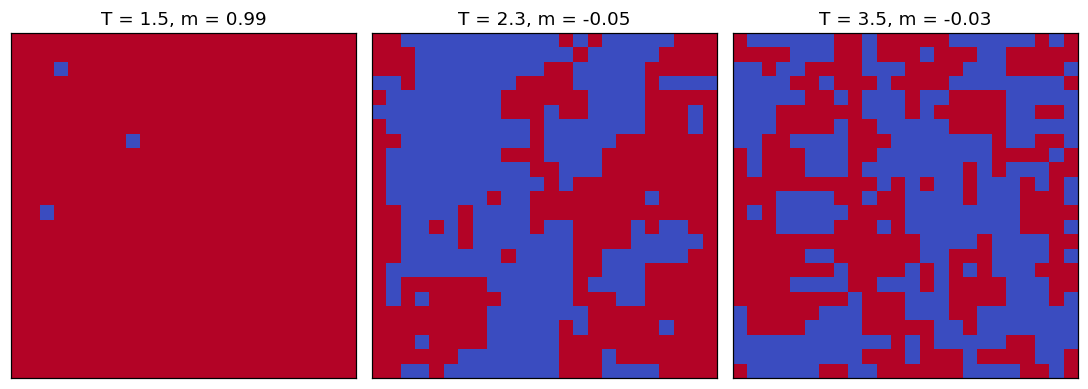

In [4]:
temperatures = [1.5, 2.3, 3.5]
plt.figure(figsize=(10, 3.5))
for i, T in enumerate(temperatures):
    grid = make_spins(24, ordered=True)
    E = total_energy(grid)
    M = total_magnetization(grid)
    # These sweeps relax the initially ordered lattice; a fixed count is not proof of equilibration.
    for sweep in range(350):
        E, M, accepted = metropolis_sweep(grid, T, E, M)
    plt.subplot(1, 3, i+1)
    plt.imshow(grid, cmap='coolwarm', vmin=-1, vmax=1, interpolation='nearest')
    plt.title('T = ' + str(T) + ', m = ' + str(round(M/grid.size, 2)))
    plt.xticks([])
    plt.yticks([])
plt.tight_layout()
plt.show()


**Pause and interpret:** Do the red/blue patches look different at low and high temperature? The simulation is random; if the middle panel looks unexpected, run it again with a different seed or allow more sweeps. A picture alone cannot locate the transition precisely.

## 5. Why do we wait before measuring?

Starting all spins up imposes an artificial initial condition. The first part of the Markov chain is used to **equilibrate** (sometimes called burn-in), and then we record measurements. Successive measurements are correlated because each configuration is generated from the previous one. Recording every 10 sweeps reduces that correlation but does **not** guarantee independent samples.

**Task.** At each temperature, discard 300 sweeps; then record energy and magnetization every 10 sweeps over another 600 sweeps. Calculate the mean $|m|$, mean energy per spin, and acceptance fraction.


In [5]:
def measure_temperature(T, L=20, warmup=300, measurement_sweeps=600, gap=10):
    grid = make_spins(L, ordered=True)
    E = total_energy(grid)
    M = total_magnetization(grid)

    # Discard the initial transient before accumulating observable measurements.
    for sweep in range(warmup):
        E, M, accepted = metropolis_sweep(grid, T, E, M)

    recorded_M = []
    recorded_E = []
    total_accepted = 0
    for sweep in range(measurement_sweeps):
        E, M, accepted = metropolis_sweep(grid, T, E, M)
        total_accepted = total_accepted + accepted
        # Retain every gap-th configuration; rejections still count as chain steps.
        # Thinning does not guarantee independence, especially near the transition.
        if (sweep + 1) % gap == 0:
            recorded_M.append(M)
            recorded_E.append(E)

    N = L*L
    # Take |M| BEFORE averaging to measure order without cancellation of up/down states.
    mean_abs_m = np.mean(np.abs(recorded_M))/N
    mean_e = np.mean(recorded_E)/N
    # Fluctuation-based quantities for a finite zero-field lattice.
    # Equilibrium fluctuation-response formula: use TOTAL M variance then divide by N*T.
    # A short chain trapped in one sign sector cannot estimate the full symmetric ensemble.
    susceptibility = (np.mean(np.array(recorded_M)**2) - np.mean(recorded_M)**2)/(N*T)
    # Likewise energy variance / (N*T**2) gives heat capacity per spin for k_B=1.
    heat_capacity = (np.mean(np.array(recorded_E)**2) - np.mean(recorded_E)**2)/(N*T**2)
    # Acceptance fraction uses ALL measurement proposals, not just the recorded samples.
    acceptance = total_accepted/(N*measurement_sweeps)
    return mean_abs_m, mean_e, susceptibility, heat_capacity, acceptance

T_values = [1.5, 1.8, 2.0, 2.15, 2.3, 2.45, 2.6, 2.9, 3.5]
results_20 = []
for T in T_values:
    result = measure_temperature(T, L=20)
    results_20.append(result)
    print('T =', T, '| <|m|> =', round(result[0], 3),
          '| <E>/N =', round(result[1], 3), '| accepted =', round(result[4], 3))


T = 1.5 | <|m|> = 0.987 | <E>/N = -1.952 | accepted = 0.013
T = 1.8 | <|m|> = 0.957 | <E>/N = -1.858 | accepted = 0.041
T = 2.0 | <|m|> = 0.914 | <E>/N = -1.749 | accepted = 0.077
T = 2.15 | <|m|> = 0.825 | <E>/N = -1.608 | accepted = 0.127
T = 2.3 | <|m|> = 0.544 | <E>/N = -1.358 | accepted = 0.227
T = 2.45 | <|m|> = 0.302 | <E>/N = -1.167 | accepted = 0.303
T = 2.6 | <|m|> = 0.224 | <E>/N = -1.007 | accepted = 0.362
T = 2.9 | <|m|> = 0.137 | <E>/N = -0.863 | accepted = 0.44
T = 3.5 | <|m|> = 0.083 | <E>/N = -0.651 | accepted = 0.554


We plot $\langle|m|\rangle$ rather than $\langle m\rangle$ because a finite, zero-field lattice can change from mostly up to mostly down: those ordered states have opposite signs and might cancel in an average. Absolute magnetization measures **how aligned** the lattice is without choosing a direction.

The infinite square-lattice model has a known critical temperature, $T_c=2J/[k_B\ln(1+\sqrt{2})]\approx2.269$ for zero external field. Our $20\times20$ grid is finite, so its curves should change **smoothly** around this value rather than jump sharply.


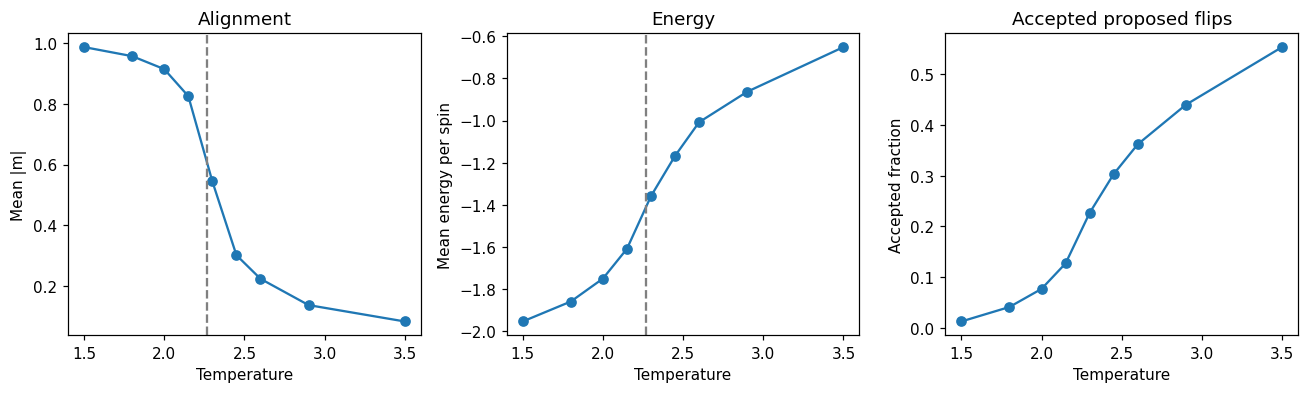

Infinite-lattice benchmark Tc = 2.269


In [6]:
# Exact infinite, isotropic square-lattice zero-field benchmark with J=k_B=1.
Tc = 2/np.log(1 + np.sqrt(2))
magnetization = [result[0] for result in results_20]
energy = [result[1] for result in results_20]
acceptance = [result[4] for result in results_20]

plt.figure(figsize=(12, 3.7))
plt.subplot(1, 3, 1)
plt.plot(T_values, magnetization, 'o-')
plt.axvline(Tc, color='gray', linestyle='--')
plt.xlabel('Temperature')
plt.ylabel('Mean |m|')
plt.title('Alignment')
plt.subplot(1, 3, 2)
plt.plot(T_values, energy, 'o-')
plt.axvline(Tc, color='gray', linestyle='--')
plt.xlabel('Temperature')
plt.ylabel('Mean energy per spin')
plt.title('Energy')
plt.subplot(1, 3, 3)
plt.plot(T_values, acceptance, 'o-')
plt.xlabel('Temperature')
plt.ylabel('Accepted fraction')
plt.title('Accepted proposed flips')
plt.tight_layout()
plt.show()
print('Infinite-lattice benchmark Tc =', round(Tc, 3))


### Reading alignment, energy, and acceptance

At low temperature, aligned spins are energetically favored, so mean absolute magnetization is large and energy per spin is close to the ground-state value (-2J). Raising temperature allows more unfavorable flips; alignment decreases and energy generally becomes less negative. In the infinite-temperature limit, uncorrelated spins give mean energy per spin zero, while a finite lattice still has nonzero typical (|m|) from fluctuations.

The acceptance fraction is a diagnostic of the update process, not an order parameter or a guarantee of independent samples. A higher fraction does not by itself demonstrate equilibration. The dashed line is the exact **infinite-lattice** critical-temperature benchmark, not a transition temperature fitted from these data.

The plotted points come from short, correlated runs with no error bars. Near the transition, relaxation can be slow (critical slowing down), so 300 discarded sweeps may not remove the initial-state dependence. Trends are illustrative; small wiggles should not be assigned a physical explanation without longer runs and uncertainty estimates. Monte Carlo sweeps are sampling steps, not calibrated physical time.


## 6. Look for fluctuations near the transition

Near the transition, large regions can rearrange and fluctuate. Two useful finite-lattice diagnostics are

$$\chi=\frac{\langle M^2\rangle-\langle M\rangle^2}{NT},\qquad
C=\frac{\langle E^2\rangle-\langle E\rangle^2}{NT^2},$$

where $N=L^2$ and $k_B=1$. These correspond to zero-field susceptibility and heat capacity **per spin**. Our short, correlated run gives only rough estimates; peaks can shift with lattice size and sampling length.


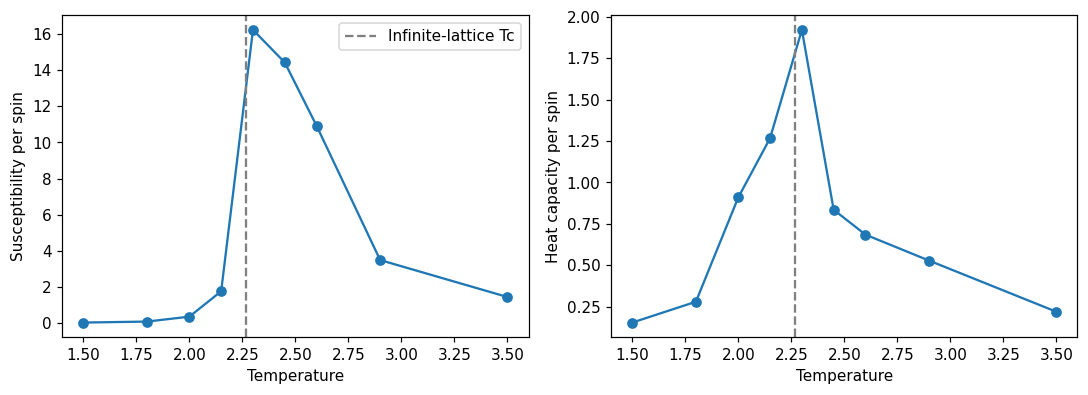

In [7]:
chi = [result[2] for result in results_20]
heat = [result[3] for result in results_20]
plt.figure(figsize=(10, 3.7))
plt.subplot(1, 2, 1)
plt.plot(T_values, chi, 'o-')
plt.axvline(Tc, color='gray', linestyle='--', label='Infinite-lattice Tc')
plt.xlabel('Temperature')
plt.ylabel('Susceptibility per spin')
plt.legend()
plt.subplot(1, 2, 2)
plt.plot(T_values, heat, 'o-')
plt.axvline(Tc, color='gray', linestyle='--')
plt.xlabel('Temperature')
plt.ylabel('Heat capacity per spin')
plt.tight_layout()
plt.show()


### Reading fluctuation estimates—and the susceptibility caveat

The heat-capacity estimator measures energy fluctuations: rearrangements that change many bonds can increase this variance near the transition. Its peak in a finite, coarsely sampled lattice can be rounded and shifted. The shown peak does not determine the infinite-lattice critical temperature precisely.

The susceptibility formula is correct for the **full equilibrium** finite zero-field ensemble. That ensemble is symmetric under reversing every spin, so its exact (langle M
angle) is zero. However, a short local-flip chain started all-up can remain in the positive-magnetization sector at low temperature. Subtracting its nonzero sample mean then measures fluctuations within that sampled sector rather than the full symmetric ensemble. This is an equilibrium-sampling limitation, not a mistake in the local flip rule.

In particular, the full finite-lattice zero-field susceptibility need not have only a peak near the critical temperature: at very low positive temperature the two almost fully ordered states give (langle M^2
angleapprox N^2), hence (chiapprox N/T). A small low-temperature value in this short run must not be interpreted as the fully equilibrated zero-field susceptibility.

Replacing (langle M
angle^2) with (langle|M|
angle^2) defines a different, often useful order-fluctuation diagnostic; it is not the same finite-lattice linear-response quantity. Here we retain the stated formula and treat the result as a rough finite-run fluctuation estimate. Neither plot includes correlation-aware error bars, and recording every ten sweeps does not remove the need for them.


## 7. Does lattice size change the picture? *(extension)*

**Task.** Repeat the magnetization measurement with a smaller $12\times12$ grid, using the same settings. The two curves will not agree at every temperature, particularly near the transition. This is a first look at **finite-size effects**, not a precise estimate of $T_c$.


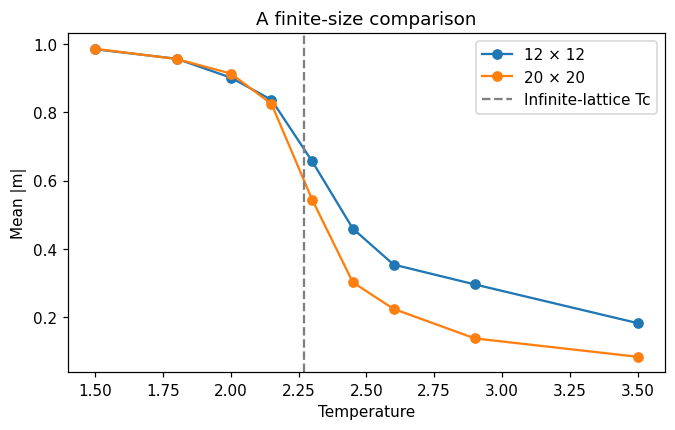

In [8]:
results_12 = []
# Repeat the same protocol at smaller L; finite-size changes and sampling noise both matter.
for T in T_values:
    results_12.append(measure_temperature(T, L=12))

plt.figure(figsize=(7, 4))
plt.plot(T_values, [result[0] for result in results_12], 'o-', label='12 × 12')
plt.plot(T_values, magnetization, 'o-', label='20 × 20')
plt.axvline(Tc, color='gray', linestyle='--', label='Infinite-lattice Tc')
plt.xlabel('Temperature')
plt.ylabel('Mean |m|')
plt.title('A finite-size comparison')
plt.legend()
plt.show()


### Reading the lattice-size comparison

Both finite lattices show a rounded loss of alignment rather than a sharp thermodynamic singularity. Differences near the benchmark may reflect finite-size effects, incomplete equilibration, and ordinary Monte Carlo sampling noise; two short runs without error bars do not separate these contributions.

Even well above the transition, a finite random lattice has nonzero mean absolute magnetization. For independent spins its typical scale is (N^{-1/2}=1/L), so a smaller lattice can have a larger residual (langle|m|
angle) without being ferromagnetically ordered. Two sizes and this coarse temperature grid are an introductory comparison, not a finite-size-scaling analysis or a precise estimate of the critical temperature.


## What you have learned

- A spin flip changes the energy through only four neighboring bonds.
- The Metropolis rule makes a **Markov chain** of correlated configurations whose long-run frequencies follow the thermal weighting (provided the simulation is run long enough).
- A Monte Carlo average then estimates observables such as magnetization and energy.
- Low-temperature configurations tend to align; higher temperatures disrupt that order. A finite lattice has rounded curves and noisy peaks near the infinite-lattice transition.

**Try next:** Increase warmup and measurement sweeps near $T\approx2.3$ and see whether the fluctuating quantities settle. Keep track of run time. To make quantitative error bars, you would also need to address correlation between samples (for example, using independent runs or block averages).

**Sources:** The Metropolis sampling rule originates in [Metropolis et al., *Journal of Chemical Physics* **21**, 1087 (1953)](https://doi.org/10.1063/1.1699114). The zero-field square-lattice transition is established in [Onsager, *Physical Review* **65**, 117 (1944)](https://doi.org/10.1103/PhysRev.65.117). The cited $T_c$ is for the infinite lattice; the plotted results are from our finite simulation.
